# Numerical Solution of the Blasius Equation Using the Shooting Method

## 1. Objective

The objective is to obtain a numerical solution of the Blasius boundary-layer equation using the shooting method.

The third-order nonlinear differential equation is converted into a system of three first-order differential equations. The resulting initial value problem is solved using the third-order Runge-Kutta (RK3) and fourth-order Runge-Kutta (RK4) methods.

The shooting method is used to determine the unknown initial condition required to satisfy the boundary conditions. The bisection method is employed to iteratively adjust this initial value.

Finally, the numerical solutions obtained using RK3 and RK4 are compared for different step sizes to study their convergence and accuracy.

## 2. Governing Equations

The Blasius equation governing the laminar boundary layer over a flat plate is given by:

$$
\frac{d^3 f}{d\eta^3}+\frac{1}{2}f\frac{d^2 f}{d\eta^2}=0
$$

The corresponding boundary conditions are:

$$
f(0)=0
$$

$$
f'(0)=0
$$

$$
f'(\eta)\rightarrow 1 \qquad \text{as } \eta\rightarrow\infty
$$

Here, (f) is the dimensionless stream function and (\eta) is the similarity variable.

For numerical computation, the infinite domain is approximated by a finite computational domain:

$$
0\leq\eta\leq 10
$$

Therefore, the boundary condition at infinity is approximated as:

$$
f'(10)\approx 1
$$

The unknown initial condition is the second derivative at the wall, given by:

$$
f''(0)=s
$$

The objective of the shooting method is to determine the value of (s) such that the solution satisfies the boundary condition at $$
(\eta = 10)
$$

## Step 1: Initialization and Problem Setup

1. The first step is to define the computational parameters required for solving the Blasius boundary-layer equation numerically by defining the initial and final boundry values:

$$
\eta_0=0,\qquad \eta_\infty=10
$$

2. Since the Blasius equation is defined over an infinite domain, the upper limit is approximated by a finite value of  $ \eta=10 $. This allows the differential equation to be integrated over a finite computational interval while approximating the boundary condition at infinity.

3. Then we use the following steps sizes:

$$
h=\{0.4,\ 0.2,\ 0.1,\ 0.05,\ 0.025\}
$$

4. Then we define the tolerance value

$$
\varepsilon=10^{-10}
$$

5. Also at the last we are displaying the values

In [15]:
import numpy as np
import matplotlib.pyplot as plt

eta_0 = 0.0      # 1st boundry condition (starting one)
eta_infinity = 10.0   # 2nd boundry condition (The last point)

step_sizes = [0.4, 0.2, 0.1, 0.05, 0.025]

tolerance = 1e-10 

print("Computational domain:", eta_0, "to", eta_infinity)
print("Step sizes:", step_sizes)
print("Shooting tolerance:", tolerance)


Computational domain: 0.0 to 10.0
Step sizes: [0.4, 0.2, 0.1, 0.05, 0.025]
Shooting tolerance: 1e-10


## Step 2: Formulation of the Blasius Differential Equation

1. The governing Blasius equation is a third-order nonlinear ordinary differential equation:

$$
f'''+\frac{1}{2}ff''=0
$$

To numerically integrate this equation using the Runge-Kutta methods, it is first converted into a system of three first-order differential equations.

Three dependent variables are introduced:

$$
y_1=f,\qquad y_2=f',\qquad y_3=f''
$$

Using these definitions, the governing equation is rewritten as:

$$
\frac{dy_1}{d\eta}=y_2
$$

$$
\frac{dy_2}{d\eta}=y_3
$$

$$
\frac{dy_3}{d\eta}=-\frac{1}{2}y_1y_3
$$

2. The result is thus stored in an array

$$
\frac{d\mathbf{Y}}{d\eta}=
\begin{bmatrix}
y_2\\
y_3\\
-\frac{1}{2}y_1y_3
\end{bmatrix}
$$

3. Then we do a test evaluation using an initial solution vector to verify that the function returns the expected derivatives.

In [16]:
def blasius_equations(eta, Y):       # creating the blasius function

    y1, y2, y3 = Y

    dy1 = y2
    dy2 = y3
    dy3 = -0.5 * y1 * y3

    return np.array([dy1, dy2, dy3])


Y_test = np.array([0.0, 0.0, 0.332])     #Testing if the function works

derivatives = blasius_equations(0.0, Y_test)

print("Initial solution vector:", Y_test)
print("Initial derivatives:", derivatives)



Initial solution vector: [0.    0.    0.332]
Initial derivatives: [ 0.     0.332 -0.   ]


## Step 3: Third-Order Runge-Kutta (RK3) Method

The system of first-order Blasius equations is numerically integrated using the third-order Runge-Kutta method.

1. The initial solution vector is defined using the initial boundary conditions:

   $$
   Y_0=
   \begin{bmatrix}
   0\\
   0\\
   s
   \end{bmatrix}
   $$

2. The computational domain is divided into discrete steps of size \(h\), and three intermediate slopes are calculated at each step:

   $$
   k_1=hG(\eta_n,Y_n)
   $$

   $$
   k_2=hG\left(\eta_n+\frac{h}{2},Y_n+\frac{k_1}{2}\right)
   $$

   $$
   k_3=hG(\eta_n+h,Y_n-k_1+2k_2)
   $$

3. The three slopes are combined to calculate the solution at the next integration point:

   $$
   Y_{n+1}=Y_n+\frac{k_1+4k_2+k_3}{6}
   $$

4. The integration process is repeated until the final computational point, $ \eta=10\ $, is reached.


In [17]:
def RK3(eta_0, eta_infinity, Y0, h):     #Defining an RK3 function

    N = int(round((eta_infinity - eta_0) / h))
    eta = np.linspace(eta_0, eta_infinity, N + 1)
    Y = np.zeros((N + 1, 3))
    Y[0] = Y0

    for i in range(N):

        k1 = h * blasius_equations(eta[i], Y[i])

        k2 = h * blasius_equations(
            eta[i] + h/2,
            Y[i] + k1/2
        )

        k3 = h * blasius_equations(
            eta[i] + h,
            Y[i] - k1 + 2*k2
        )

        Y[i+1] = Y[i] + (k1 + 4*k2 + k3)/6

    return eta, Y


Y0_test = np.array([0.0, 0.0, 0.332])     #Testing

eta_test, Y_test = RK3(
    eta_0,
    eta_infinity,
    Y0_test,
    0.1
)

print("Final values using RK3:")
print("f(eta_infinity)   =", Y_test[-1, 0])
print("f'(eta_infinity)  =", Y_test[-1, 1])
print("f''(eta_infinity) =", Y_test[-1, 2])



Final values using RK3:
f(eta_infinity)   = 8.278184867449003
f'(eta_infinity)  = 0.99988649492211
f''(eta_infinity) = 8.238392781356104e-09


## Step 4: Fourth-Order Runge-Kutta (RK4) Method

In this section, the same system of first-order Blasius equations is integrated using the fourth-order Runge-Kutta method.

1. The initial solution vector is defined using the boundary conditions:

   $$
   Y_0=
   \begin{bmatrix}
   0\\
   0\\
   s
   \end{bmatrix}
   $$

2. Four intermediate slopes are calculated at each integration step:

   $$
   k_1=hG(\eta_n,Y_n)
   $$

   $$
   k_2=hG\left(\eta_n+\frac{h}{2},Y_n+\frac{k_1}{2}\right)
   $$

   $$
   k_3=hG\left(\eta_n+\frac{h}{2},Y_n+\frac{k_2}{2}\right)
   $$

   $$
   k_4=hG(\eta_n+h,Y_n+k_3)
   $$

3. These slopes are combined to calculate the solution at the next integration point:

   $$
   Y_{n+1}=Y_n+\frac{k_1+2k_2+2k_3+k_4}{6}
   $$

4. The integration is repeated over the entire computational domain until \(\eta=10\) is reached.

5. The solution array is initialized and maintained using double-precision floating-point values (`float64`) to explicitly ensure double-precision numerical representation.

6. The function returns the similarity coordinate array and the corresponding numerical solutions of all three dependent variables.

In [43]:
def RK4(eta_0, eta_infinity, Y0, h):           # Created an RK4 function

    Y0 = np.asarray(Y0, dtype=np.float64)
    N = int(round((eta_infinity - eta_0) / h))
    eta = np.linspace(eta_0, eta_infinity, N + 1)
    Y = np.zeros((N + 1, 3), dtype=np.float64)
    Y[0] = Y0

    for i in range(N):

        k1 = h * blasius_equations(eta[i], Y[i])

        k2 = h * blasius_equations(
            eta[i] + h/2,
            Y[i] + k1/2
        )

        k3 = h * blasius_equations(
            eta[i] + h/2,
            Y[i] + k2/2
        )

        k4 = h * blasius_equations(
            eta[i] + h,
            Y[i] + k3
        )

        Y[i+1] = Y[i] + (k1 + 2*k2 + 2*k3 + k4)/6

    return eta, Y

Y0_test = np.array([0.0, 0.0, 0.332])             #Testing RK4 function

eta_test_RK4, Y_test_RK4 = RK4(
    eta_0,
    eta_infinity,
    Y0_test,
    0.1
)

print("Final values using RK4:")
print("f(eta_infinity)   =", Y_test_RK4[-1, 0])
print("f'(eta_infinity)  =", Y_test_RK4[-1, 1])
print("f''(eta_infinity) =", Y_test_RK4[-1, 2])



Final values using RK4:
f(eta_infinity)   = 8.278160196441748
f'(eta_infinity)  = 0.9998848647428862
f''(eta_infinity) = 8.477515748867367e-09


In [42]:
def shooting_method(integration_method, h):   #implementing the shotting method using the bisection method

    # Initial bracket for the shooting parameter
    s_low = 0.3
    s_high = 0.4

    # Function to calculate the residual
    def residual(s):

        Y0 = np.array([0.0, 0.0, s])

        eta, Y = integration_method(
            eta_0, eta_infinity, Y0, h
        )

        return Y[-1, 1] - 1.0

    F_low = residual(s_low)            #residual calculation
    F_high = residual(s_high)

    if F_low * F_high > 0:
        raise ValueError("Bisection interval does not bracket a root.")

    iteration = 0         # Bisection iterations
    max_iterations = 100

    while iteration < max_iterations:

        s_mid = (s_low + s_high) / 2

        F_mid = residual(s_mid)

        if abs(F_mid) < tolerance:
            break

        if F_low * F_mid < 0:

            s_high = s_mid
            F_high = F_mid

        else:

            s_low = s_mid
            F_low = F_mid

        iteration += 1

    return s_mid, F_mid, iteration




In [24]:
RK3_results = []       # We calculate the shooting parameter using RK3 here
RK3_residuals = []
RK3_iterations = []
for h in step_sizes:

    s, residual, iterations = shooting_method(RK3, h)

    RK3_results.append([h, s, residual, iterations])


print("Results using RK3:")
print("-" * 65)
print("{:<15} {:<20} {:<20} {:<10}".format(
    "Step Size", "Shooting Parameter", "Residual", "Iterations"
))
print("-" * 65)

for result in RK3_results:

    print("{:<15} {:<20.10f} {:<20.3e} {:<10}".format(
        result[0], result[1], result[2], result[3]
    ))

Results using RK3:
-----------------------------------------------------------------
Step Size       Shooting Parameter   Residual             Iterations
-----------------------------------------------------------------
0.4             0.3319771448         8.997e-11            28        
0.2             0.3320495983         3.405e-11            29        
0.1             0.3320565334         -8.417e-11           28        
0.05            0.3320572476         -3.347e-12           29        
0.025           0.3320573267         -8.327e-11           27        


In [25]:
# implementing RK4 for different step sizes
RK4_solutions = []
RK4_residuals = []
RK4_iterations = []

# Calculate the shooting parameter for each step size
for h in step_sizes:

    s, residual_value, iterations = shooting_method(RK4, h)

    RK4_solutions.append(s)
    RK4_residuals.append(residual_value)
    RK4_iterations.append(iterations)

print("Results using RK4")
print("------------------------------------------------")
print("Step Size       Shooting Parameter       Residual")

for i in range(len(step_sizes)):

    print(
        step_sizes[i], "          ",
        RK4_solutions[i], "          ",
        RK4_residuals[i]
    )

Results using RK4
------------------------------------------------
Step Size       Shooting Parameter       Residual
0.4            0.332058815844357            1.0587086762825493e-11
0.2            0.3320574574172496            -6.693434695392853e-11
0.1            0.3320573456585407            9.635670039642719e-11
0.05            0.33205733774229873            -3.001410231462387e-11
0.025            0.3320573372766375            7.520095657298498e-11


In [26]:
# Calculate a highly accurate reference solution

# Temporarily reduce the shooting tolerance
original_tolerance = tolerance
tolerance = 1e-13

# Calculate the reference shooting parameter using RK4
s_reference, reference_residual, reference_iterations = shooting_method(
    RK4, 0.0015625
)

# Restore the original tolerance
tolerance = original_tolerance

print("Reference shooting parameter:", s_reference)
print("Reference residual:", reference_residual)

Reference shooting parameter: 0.332057337203696
Reference residual: -1.0325074129013956e-14


In [29]:
# Now, for absolute error

RK3_errors = np.abs(
    np.array([result[1] for result in RK3_results]) - s_reference
)

RK4_errors = np.abs(
    np.array(RK4_solutions) - s_reference
)


print("Convergence results")
print("-" * 55)
print("{:<15} {:<20} {:<20}".format(
    "Step Size", "RK3 Error", "RK4 Error"
))

for i in range(len(step_sizes)):

    print("{:<15} {:<20.6e} {:<20.6e}".format(
        step_sizes[i], RK3_errors[i], RK4_errors[i]
    ))

Convergence results
-------------------------------------------------------
Step Size       RK3 Error            RK4 Error           
0.4             8.019239e-05         1.478641e-06        
0.2             7.738938e-06         1.202136e-07        
0.1             8.038447e-07         8.454845e-09        
0.05            8.961342e-08         5.386027e-10        
0.025           1.054414e-08         7.294149e-11        


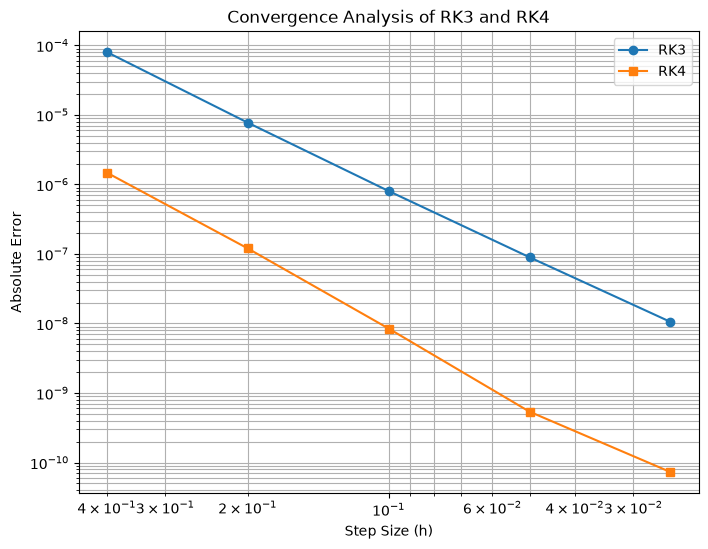

In [37]:
#Showing log-log convergence plot

plt.figure(figsize=(8, 6))

plt.loglog(
    step_sizes,
    RK3_errors,
    'o-',
    label='RK3'
)

plt.loglog(
    step_sizes,
    RK4_errors,
    's-',
    label='RK4'
)

plt.xlabel('Step Size (h)')
plt.ylabel('Absolute Error')
plt.title('Convergence Analysis of RK3 and RK4')

plt.grid(True, which='both')
plt.legend()
plt.gca().invert_xaxis()

plt.show()

In [35]:
#Observed order of accuracy

RK3_order = np.polyfit(
    np.log(step_sizes),
    np.log(RK3_errors),
    1
)[0]

RK4_order = np.polyfit(
    np.log(step_sizes),
    np.log(RK4_errors),
    1
)[0]


print("Observed order of accuracy \n")
print("RK3 order =", RK3_order)
print("RK4 order =", RK4_order)

Observed order of accuracy 

RK3 order = 3.2217894485807608
RK4 order = 3.641650707997406


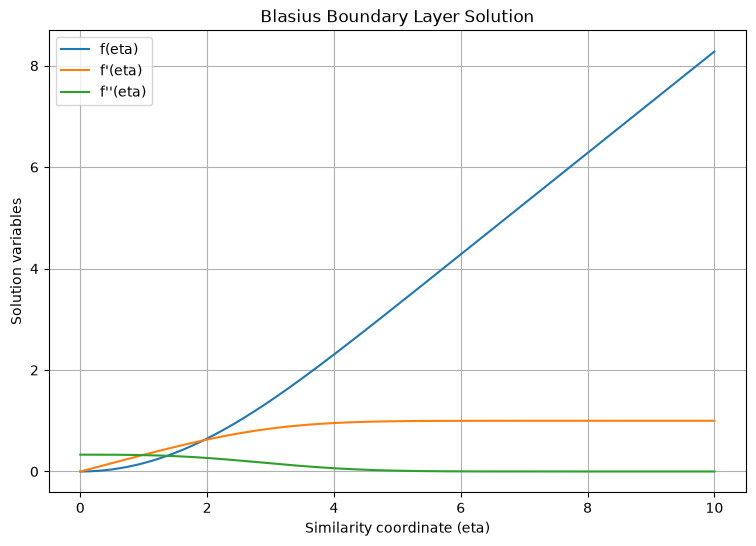

In [38]:
#Plotting the blasius function solutions

h = 0.025

s = RK4_solutions[-1]   #shooting parameter

# Initial conditions
Y0 = np.array([0.0, 0.0, s])

eta, Y = RK4(eta_0, eta_infinity, Y0, h)   #using RK4 function


# Ploting all solution variables
plt.figure(figsize=(9, 6))

plt.plot(eta, Y[:, 0], label="f(eta)")
plt.plot(eta, Y[:, 1], label="f'(eta)")
plt.plot(eta, Y[:, 2], label="f''(eta)")

plt.xlabel("Similarity coordinate (eta)")
plt.ylabel("Solution variables")
plt.title("Blasius Boundary Layer Solution")

plt.grid(True)
plt.legend()

plt.show()